# Tour: listening to and looking inside the cello models

This notebook lets you **listen** to the system and **see** what it is doing. No machine-learning background needed.
Run the cells from top to bottom (in Jupyter or Google Colab, from a copy of this repository) and press play on each audio player.

The idea in one sentence: the system squeezes real cello recordings into a compact code, learns how notes turn into expressive
playing, and can then write new music and perform it itself.

In [1]:
import numpy as np, soundfile as sf, matplotlib.pyplot as plt
from IPython.display import Audio, Image, display, Markdown
A = "docs/assets"                      # figures and short audio clips live here
def listen(name, label):
    display(Markdown(f"**{label}**")); y, sr = sf.read(f"{A}/audio/{name}.wav"); display(Audio(y, rate=sr))
def waveform(name, label, seconds=8, color="#2a78d6"):
    y, sr = sf.read(f"{A}/audio/{name}.wav"); y = y[: seconds * sr]; t = np.arange(len(y)) / sr
    plt.figure(figsize=(11, 1.6)); plt.plot(t, y, lw=0.4, color=color); plt.yticks([]); plt.xlabel("seconds"); plt.title(label, loc="left"); plt.gca().spines[["top", "right", "left"]].set_visible(False); plt.show()

## 1. Compressing a real recording

Below is 12 seconds of a famous recording that the system **never heard during training** (Mischa Maisky playing Bach), and the
same passage **rebuilt from the system's compact code**. The code describes the sound with just 24 numbers, 25 times per second.
Compare by ear first.

In [2]:
listen("1_original_maisky", "Original recording")
listen("2_codec_reconstruction", "Rebuilt from the compact code")

**Original recording**

**Rebuilt from the compact code**

**Reading the picture:** the top row is the *waveform* (how the air pressure moves over time; taller means louder). The bottom row is a
*spectrogram*: time runs left to right, pitch runs bottom to top, and brightness shows how loud each frequency is. The stacked
horizontal lines are the cello's harmonics. If the two sides look alike, the code has kept what matters.

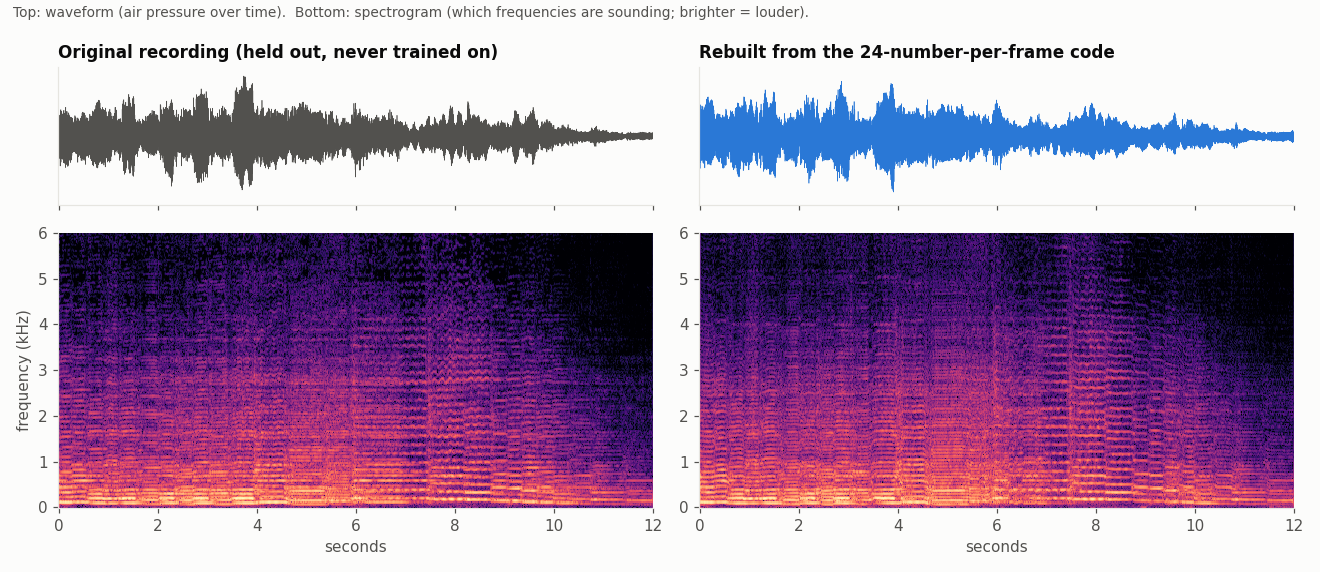

In [3]:
display(Image(f"{A}/codec_compare.png"))

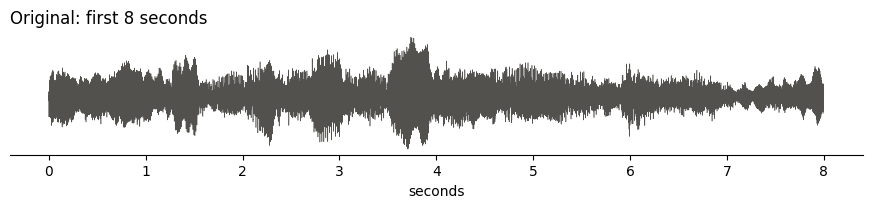

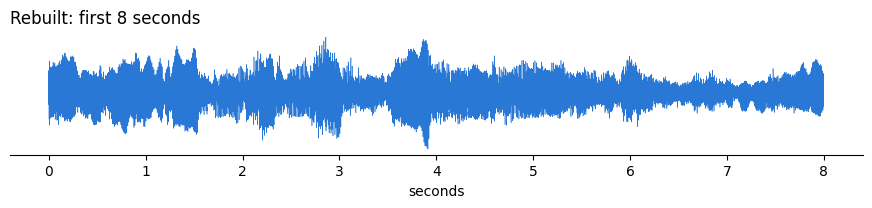

In [4]:
waveform("1_original_maisky", "Original: first 8 seconds", color="#52514e")
waveform("2_codec_reconstruction", "Rebuilt: first 8 seconds")

## 2. What the compact code looks like (the "embedding")

Every 40 milliseconds the system writes down 24 numbers that describe the sound at that moment. That list of numbers is a point in a
24-dimensional space, and as the music plays the point moves, tracing a path.

- **Left:** the path squashed down to 2 dimensions so we can see it. Each dot is a moment, coloured by the note being played.
  Similar sounds land near each other: low notes in one region, high notes in another.
- **Right:** all 24 numbers over time (red = high, blue = low). Some channels change smoothly with the phrasing; others flicker with
  the bow.

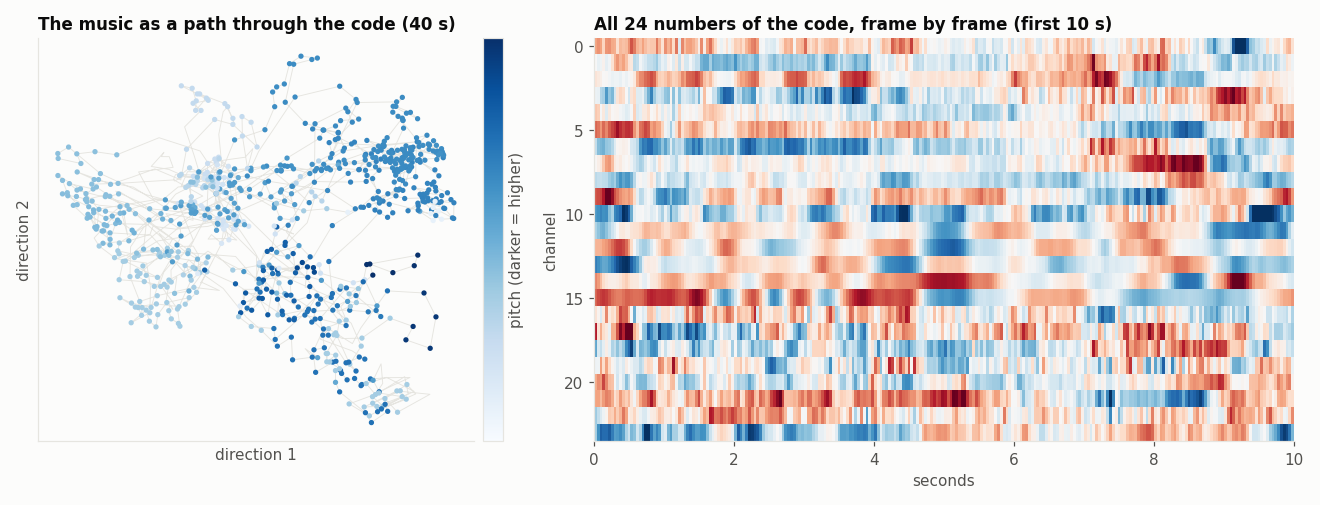

In [5]:
display(Image(f"{A}/embedding.png"))

**Which numbers matter?** We nudged each of the 24 numbers by the same amount and measured how much the sound and the pitch changed.
After regularization, every channel affects the *sound* by a similar amount (good for building generators on top), and *pitch* lives in
a few dedicated channels, which makes the code easier to interpret.

**Watching new music move through the space (UMAP).** UMAP flattens the 24 numbers onto a 2D map while keeping similar moments close
together. We fit the map on about 50,000 moments from the training recordings (blue, darker = higher pitch), then placed the held-out
Maisky passage on it moment by moment (orange). Play the clip and watch the dot jump between neighbourhoods as the notes change.

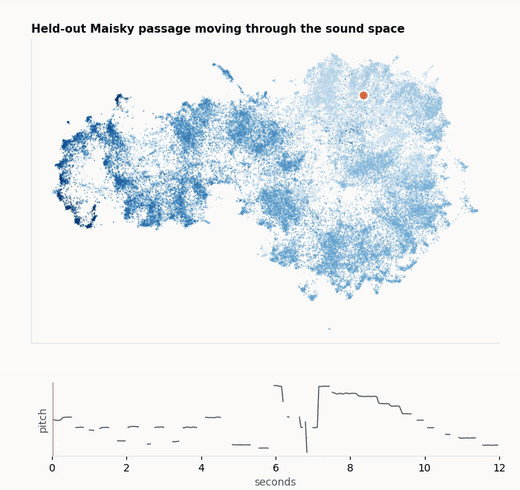

In [6]:
display(Image(f"{A}/umap_path.gif"))

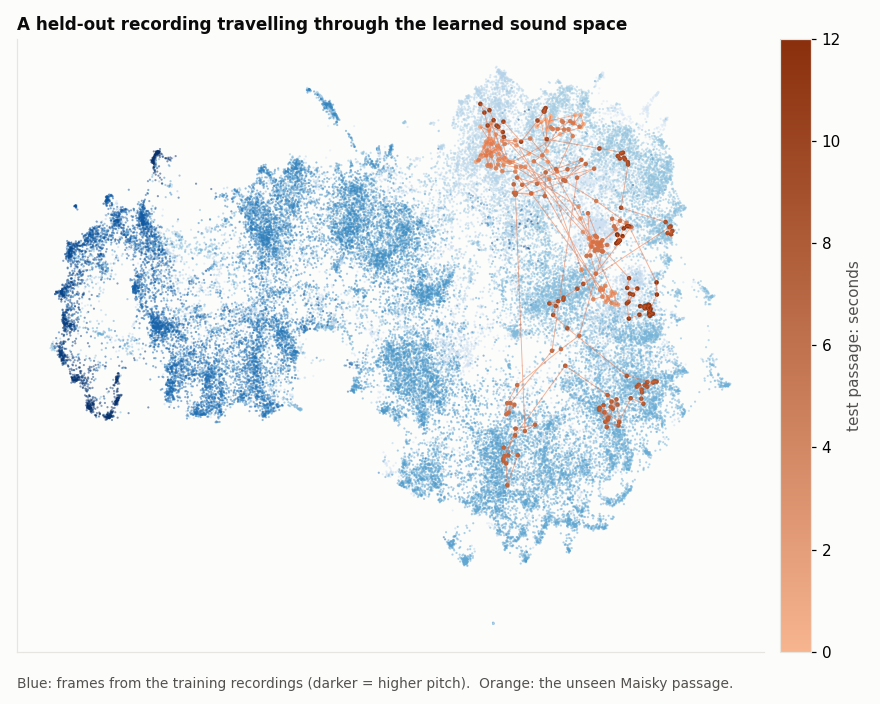

In [7]:
display(Image(f"{A}/umap_path.png"))

In [8]:
from IPython.display import Video
display(Video(f"{A}/audio/8_umap_path.mp4", embed=False, width=520))   # the same animation with the original audio

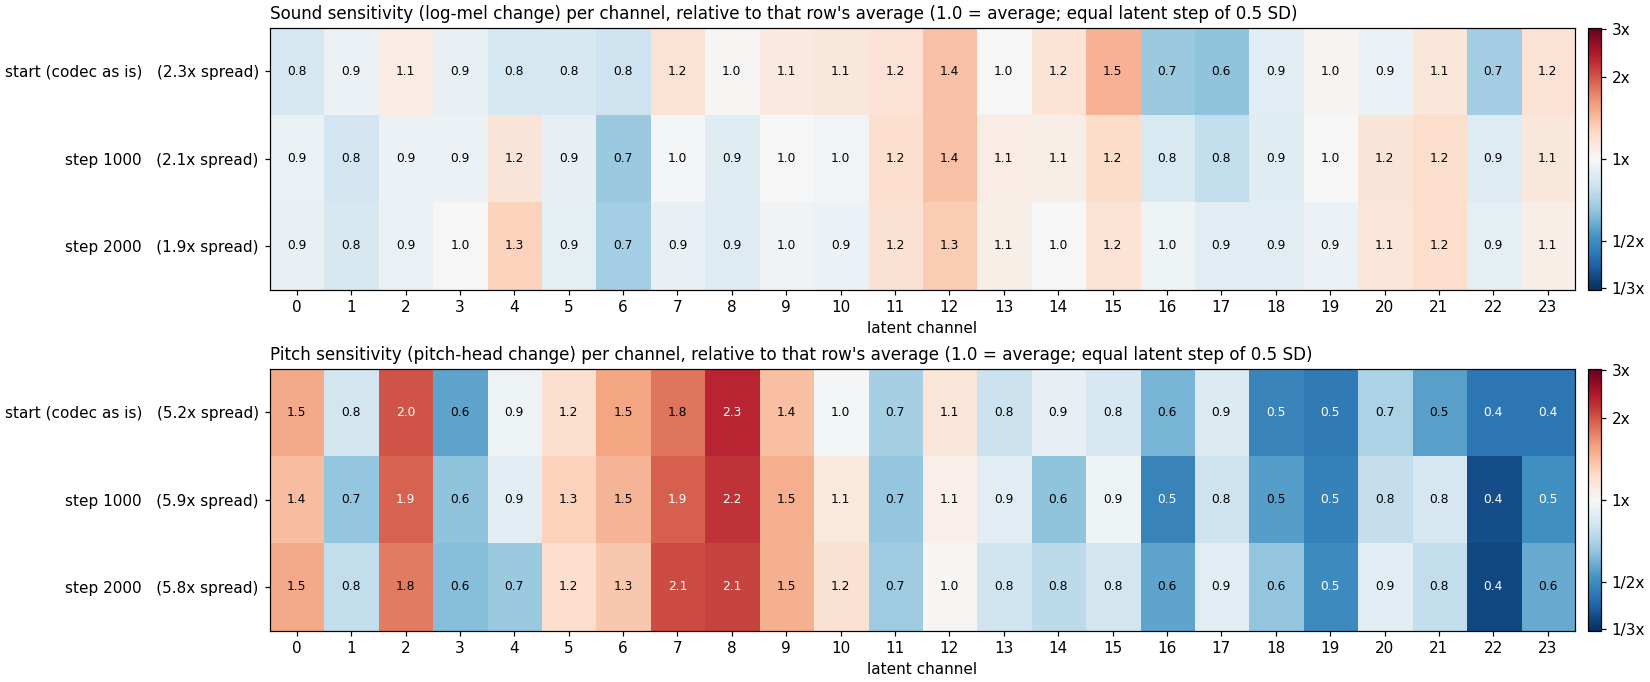

In [9]:
display(Image(f"{A}/channel_sensitivity.png"))

## 3. From written notes to a living performance

Sheet music only says *which* note and *when*. A cellist adds slides between notes, vibrato and swells in loudness. Here the system was
given only the notes of the Maisky passage (orange) and decided how to play them (blue). It never saw this recording.

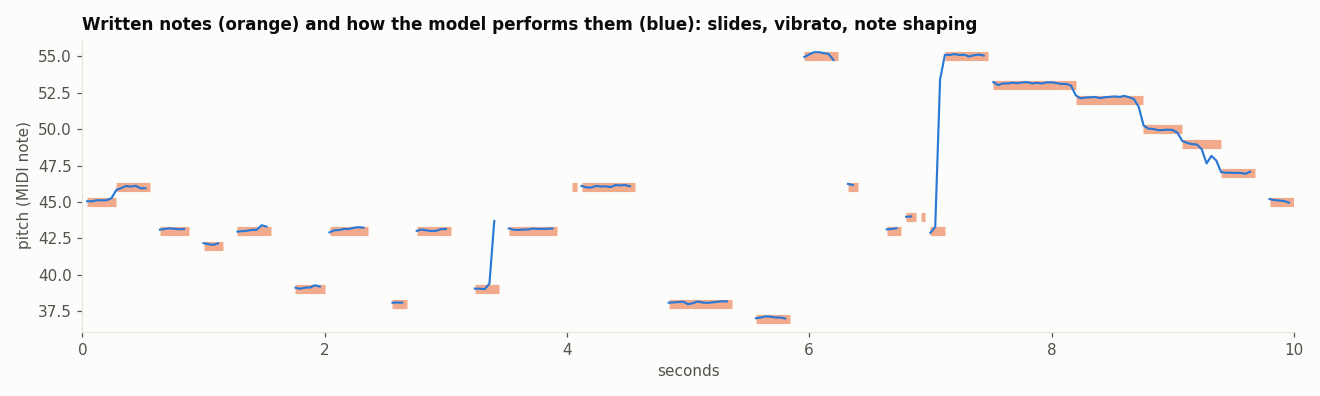

In [10]:
display(Image(f"{A}/notes_to_performance.png"))

In [11]:
listen("3_performed_from_notes_maisky", "The system performing the passage from its notes alone")
listen("1_original_maisky", "For comparison: Maisky's real performance")

**The system performing the passage from its notes alone**

**For comparison: Maisky's real performance**

## 4. Music the system composed itself

A separate model learned melody, rhythm, key and meter from about a million notes of public-domain melodies (folk airs, Bach chorales)
and the Bach cello suites. You choose a key, a time signature and a style; it writes the notes, and the rest of the system performs them
on its learned cello. Nothing below exists in any training data.

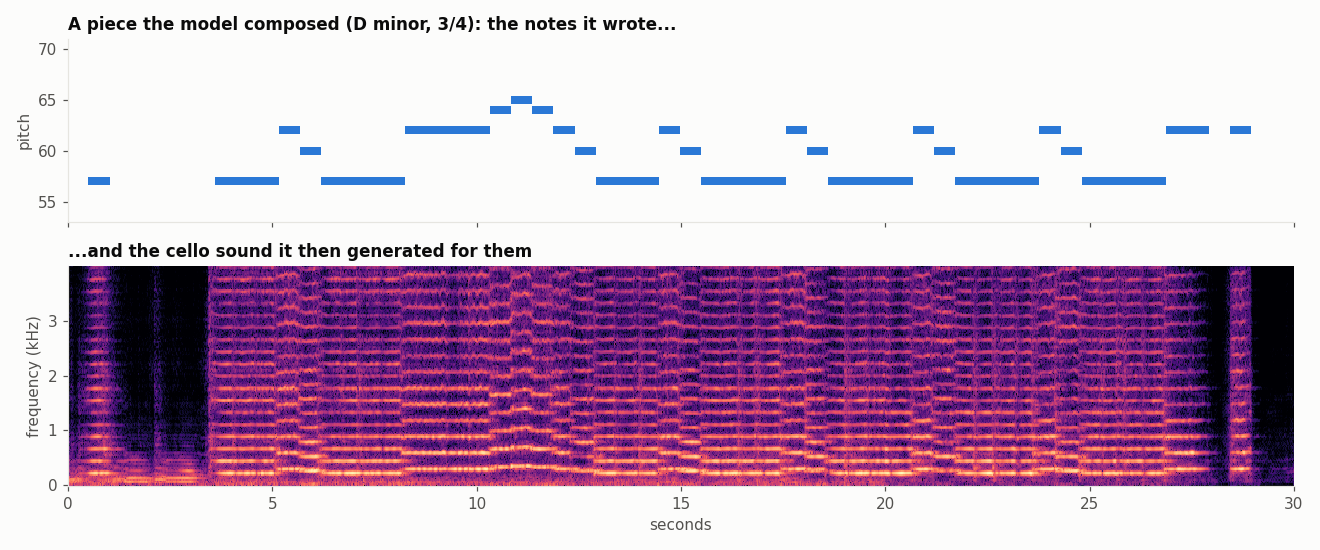

In [12]:
display(Image(f"{A}/generated_piece.png"))

In [13]:
listen("4_composed_air_dminor", "An air in D minor (3/4)")
listen("5_composed_air_gmajor", "An air in G major (4/4)")
listen("6_composed_chorale_dminor", "A chorale-style melody in D minor (4/4)")
listen("7_composed_suite_style_gmajor", "A busier piece in the style of the Bach cello suites (G major)")

**An air in D minor (3/4)**

**An air in G major (4/4)**

**A chorale-style melody in D minor (4/4)**

**A busier piece in the style of the Bach cello suites (G major)**

## 5. How good is it? (the short version)

| Test | Result |
|---|---|
| Pitch accuracy when rebuilding the held-out recording | within about 7 cents (a cent is 1/100 of a semitone) |
| Bit rate of the quantized codec | 1,800 bits per second (a phone call is about 8,000) |
| Pitch accuracy when performing notes from their score | 93–94% of the time within a quarter of a semitone |
| Copying in composed music | never more than 16 notes in a row from any single training melody |

Full details, design decisions and honest limitations are in the [README](README.md) and the lab notebook (`v2/LAB_NOTEBOOK.md`).